In [ ]:
import pandas as pd

In [ ]:
project = pd.read_csv("/content/archive (1).zip")

In [ ]:
project.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [ ]:
project.shape

(55500, 15)

In [ ]:
project.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), object(12)
memory usage: 6.4

In [ ]:
project.isnull().sum()

,0
Name,0
Age,0
Gender,0
Blood Type,0
Medical Condition,0
Date of Admission,0
Doctor,0
Hospital,0
Insurance Provider,0
Billing Amount,0


In [ ]:
project.duplicated().sum()

np.int64(534)

In [ ]:
project.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [ ]:
project.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='object')

In [ ]:
project.dtypes

,0
Name,object
Age,int64
Gender,object
Blood Type,object
Medical Condition,object
Date of Admission,object
Doctor,object
Hospital,object
Insurance Provider,object
Billing Amount,float64


In [ ]:
project.duplicated().sum()

np.int64(534)

In [ ]:
project = project.drop_duplicates()

In [ ]:
project.duplicated().sum()

np.int64(0)

In [ ]:
project[['Date of Admission', 'Discharge Date']].dtypes

,0
Date of Admission,object
Discharge Date,object


In [ ]:
project['Date of Admission'] = pd.to_datetime(project['Date of Admission'])
project['Discharge Date'] = pd.to_datetime(project['Discharge Date'])

In [ ]:
project[['Date of Admission', 'Discharge Date']].dtypes

,0
Date of Admission,datetime64[ns]
Discharge Date,datetime64[ns]


In [ ]:
project['Length of Stay'] = (
    project['Discharge Date'] - project['Date of Admission']
).dt.days

In [ ]:
project[['Date of Admission', 'Discharge Date', 'Length of Stay']].head()

,Date of Admission,Discharge Date,Length of Stay
0,2024-01-31,2024-02-02,2
1,2019-08-20,2019-08-26,6
2,2022-09-22,2022-10-07,15
3,2020-11-18,2020-12-18,30
4,2022-09-19,2022-10-09,20


In [ ]:
project['Length of Stay'].describe()

,Length of Stay
count,54966.000000
mean,15.499290
std,8.661471
min,1.000000
25%,8.000000
50%,15.000000
75%,23.000000
max,30.000000


In [ ]:
project[project['Length of Stay'] < 0]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay


In [ ]:
project['Length of Stay'].min()

1

In [ ]:
project['Length of Stay'].max()

30

In [ ]:
project['Billing Amount'].min()

-2008.4921398591305

In [ ]:
project['Billing Amount'].max()

52764.276736469175

In [ ]:
project['Billing Amount'].mean()

np.float64(25544.306284383965)

In [ ]:
project[project['Billing Amount'] < 0]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay
132,ashLEy ERIcKSoN,32,Female,AB-,Cancer,2019-11-05,Gerald Hooper,"and Johnson Moore, Branch",Aetna,-502.507813,376,Urgent,2019-11-23,Penicillin,Normal,18
799,CHRisTOPHer wEiss,49,Female,AB-,Asthma,2023-02-16,Kelly Thompson,Hunter-Hughes,Aetna,-1018.245371,204,Elective,2023-03-09,Penicillin,Inconclusive,21
1018,AsHley WaRnER,60,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal,21
1421,JAY galloWaY,74,Female,O+,Asthma,2021-01-20,Debra Everett,Group Peters,Blue Cross,-109.097122,381,Emergency,2021-02-09,Ibuprofen,Abnormal,20
2103,josHUa wilLIamSon,72,Female,B-,Diabetes,2021-03-21,Wendy Ramos,"and Huff Reeves, Dennis",Blue Cross,-576.727907,369,Urgent,2021-04-17,Aspirin,Abnormal,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52213,mr. ChRIStOPhER aLvARaDO,74,Male,AB+,Obesity,2022-06-03,Mr. Dean Guzman DDS,Johnson Inc,Blue Cross,-1310.272895,257,Elective,2022-06-13,Paracetamol,Inconclusive,10
52629,gABrieLlE deCkER,66,Male,AB-,Arthritis,2022-11-07,William Krause,Diaz-Bishop,Cigna,-676.852502,354,Urgent,2022-11-30,Penicillin,Normal,23
53204,AsHley WaRnER,55,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal,21
53232,dAnIel dRaKe,68,Female,B+,Hypertension,2020-04-24,Brett Ray,Carr Ltd,Aetna,-591.917419,426,Elective,2020-04-26,Lipitor,Abnormal,2


In [ ]:
project[project['Billing Amount'] < 0].shape[0]

106

In [ ]:
project[project['Billing Amount'] < 0][['Billing Amount']]

,Billing Amount
132,-502.507813
799,-1018.245371
1018,-306.364925
1421,-109.097122
2103,-576.727907
...,...
52213,-1310.272895
52629,-676.852502
53204,-306.364925
53232,-591.917419


In [ ]:
project[project['Billing Amount'] < 0]['Billing Amount'].describe()

,Billing Amount
count,106.000000
mean,-502.472497
std,429.857027
min,-2008.492140
25%,-803.004972
50%,-374.840042
75%,-149.074654
max,-23.866729


In [ ]:
project = project[project['Billing Amount'] >= 0]

In [ ]:
project['Billing Amount'].min()

9.238787497393332

In [ ]:
project.shape

(54860, 16)

In [ ]:
# Check missing values
print("Missing values:")
print(project.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(project.duplicated().sum())

# Check categorical columns
print("\nGender:")
print(project['Gender'].value_counts())

print("\nMedical Condition:")
print(project['Medical Condition'].value_counts())

print("\nAdmission Type:")
print(project['Admission Type'].value_counts())

print("\nTest Results:")
print(project['Test Results'].value_counts())

Missing values:
Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
Length of Stay        0
dtype: int64

Duplicate rows:
0

Gender:
Gender
Male      27449
Female    27411
Name: count, dtype: int64

Medical Condition:
Medical Condition
Arthritis       9207
Diabetes        9197
Hypertension    9131
Obesity         9127
Cancer          9121
Asthma          9077
Name: count, dtype: int64

Admission Type:
Admission Type
Elective     18437
Urgent       18353
Emergency    18070
Name: count, dtype: int64

Test Results:
Test Results
Abnormal        18399
Normal          18302
Inconclusive    18159
Name: count, dtype: int64


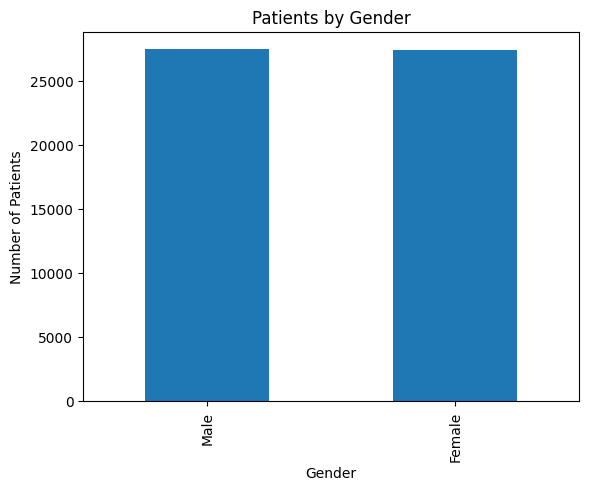

In [ ]:
import matplotlib.pyplot as plt

project['Gender'].value_counts().plot(kind='bar')

plt.title('Patients by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.show()

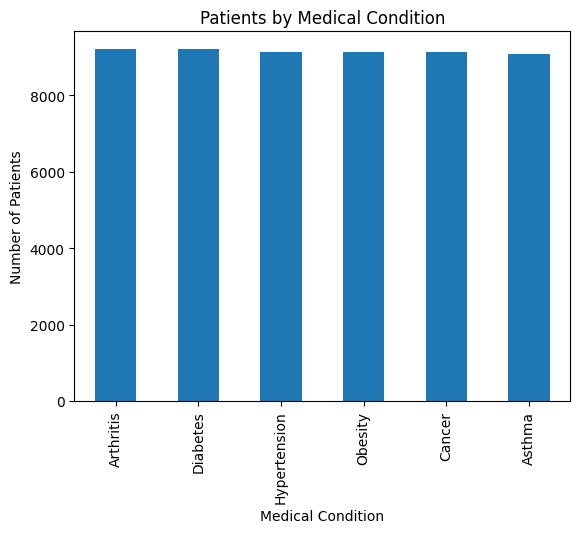

In [ ]:
project['Medical Condition'].value_counts().plot(kind='bar')

plt.title('Patients by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of Patients')
plt.show()

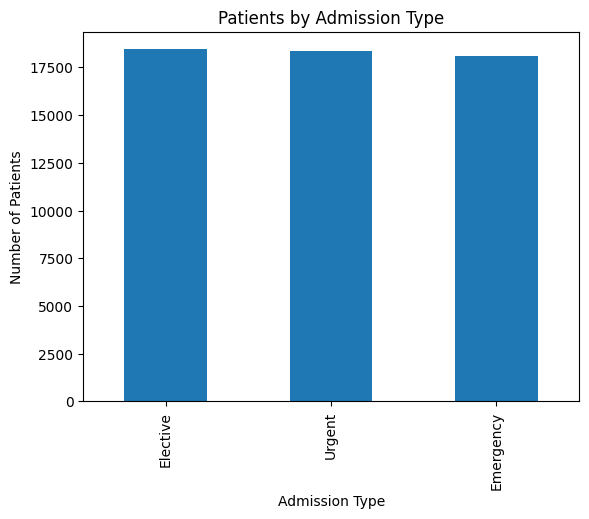

In [ ]:
project['Admission Type'].value_counts().plot(kind='bar')

plt.title('Patients by Admission Type')
plt.xlabel('Admission Type')
plt.ylabel('Number of Patients')
plt.show()

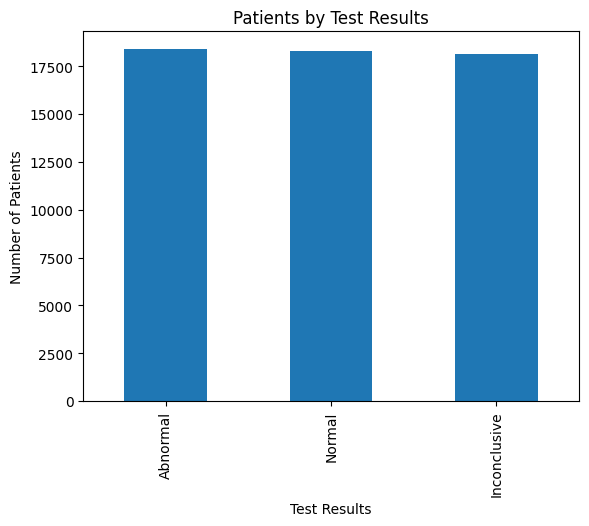

In [ ]:
project['Test Results'].value_counts().plot(kind='bar')

plt.title('Patients by Test Results')
plt.xlabel('Test Results')
plt.ylabel('Number of Patients')
plt.show()

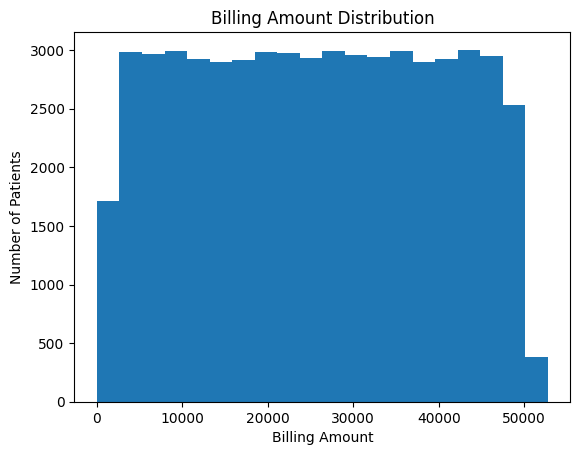

In [ ]:
project['Billing Amount'].plot(kind='hist', bins=20)

plt.title('Billing Amount Distribution')
plt.xlabel('Billing Amount')
plt.ylabel('Number of Patients')
plt.show()

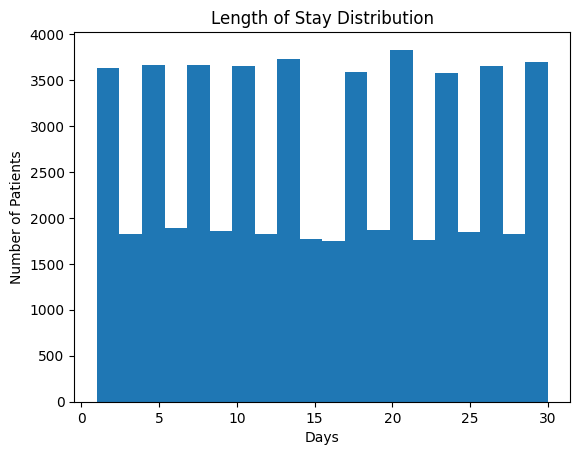

In [ ]:
project['Length of Stay'].plot(kind='hist', bins=20)

plt.title('Length of Stay Distribution')
plt.xlabel('Days')
plt.ylabel('Number of Patients')
plt.show()

In [ ]:
project.to_csv("/content/archive (1).zip", index=False)

In [ ]:
print("File saved successfully!")

File saved successfully!


In [ ]:
import os

print(os.getcwd())

/content


In [ ]:
print(os.listdir())

['.config', 'archive (1).zip', 'sample_data']


In [ ]:
print(os.path.exists("/content/archive (1).zip"))

True


In [ ]:
import os

print(os.path.abspath("/content/archive (1).zip"))

/content/archive (1).zip


In [ ]:
project.to_csv(r"C:\Users\YourName\Desktop\healthcare_cleaned.csv", index=False)

In [ ]:
project.to_csv(r"C:\Users\Najib\Desktop\healthcare_cleaned.csv", index=False)

In [59]:
import os

size = os.path.getsize("/content/archive (1).zip")

print("File size:", size / (1024 * 1024), "MB")

File size: 2.913045883178711 MB


In [60]:
!pip install mysql-connector-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.7/21.7 MB 21.0 MB/s eta 0:00:00


In [62]:
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="YOUR_MYSQL_PASSWORD",
    database="healthcare_analytics"
)

cursor = conn.cursor()

print("MySQL connected successfully!")

InterfaceError: 2003: Can't connect to MySQL server on 'localhost:3306' (Errno 111: Connection refused)

In [63]:
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="YOUR_MYSQL_PASSWORD",
    database="healthcare_analytics"
)

cursor = conn.cursor()

print("MySQL connected successfully!")

InterfaceError: 2003: Can't connect to MySQL server on 'localhost:3306' (Errno 111: Connection refused)